# Live transmit and spectrum with the hardware DDS

The DDS overlay transmits a tone *continuously*: once `dds.set(...)` has been called the FPGA keeps generating it, with no Python in the loop.
This notebook starts that tone and shows what the receiver sees **in real time**: a live spectrum, a waterfall of the last 60 frames, and sliders
for frequency, amplitude, on/off and a frequency sweep. Moving a slider changes the tone in the FPGA within a fraction of a millisecond.

**Before you start:** the same overlay and setup as `P501_DDS_Tutorial.ipynb` (folder `p501_dds`, TX1 and RX1 antennas near each other or a cable with at least 40 dB attenuation:
never connect them directly). **The tone stays on until you turn it off**: even if you close the browser tab or this notebook stops with an error. The last cell
(*Stop and silence*) turns it off; run it when you are done.

1. Run the cells down to *Self-test* (about a minute: the AD9361 bring-up is the same as in the tutorial notebook).
2. Run *Controls* and press **Start**.
3. When finished, press **Stop** and run *Stop and silence*.

## Configuration, overlay and bring-up (the same as the tutorial notebook)

In [1]:
BIT       = "/home/xilinx/jupyter_notebooks/p501_dds/p501_dds.bit"   # overlay you built (the .hwh must sit next to it)
FS        = 3_840_000          # sample rate (3.84 MSPS preset of the AD9361 driver)
LO        = 700_000_000        # RF centre frequency, Hz
RF_BW     = 4_000_000          # analog bandwidth, Hz
TX_ATTEN  = 10                 # dB
RX_GAIN   = 45                 # gain-table index 0..76
SETTLE_DB = 45                 # image rejection the AD9361 bring-up waits for (see P501_AD9361_Test.ipynb)
N_CAP     = 8192               # samples per ADC capture

In [2]:
import sys, time
import numpy as np
import matplotlib.pyplot as plt
from pynq import Overlay, allocate

sys.path.insert(0, '/home/xilinx/jupyter_notebooks')
sys.path.insert(0, '/home/xilinx/jupyter_notebooks/p501_dds')
from ad9361_driver import (AD9361, FIR_RX1, FIR_TX1,
                           REG_ENSM_CONFIG_1, TO_ALERT, FORCE_ALERT_STATE)
from axi_dmac import AxiDmac
import ad9361_full_bypass_test as fb
from ad9361_fir_test import make_fir_coef
from p501_dds import P501Dds

results = {}
def check(name, ok, detail):
    results[name] = (bool(ok), detail)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: {detail}")

ol  = Overlay(BIT)                               # loads the bitstream with the DDS
rxd = AxiDmac(ol.axi_ad9361_adc_dma)             # raw ADC capture (unchanged DMA of the base design)
dds = P501Dds(ol.dds_regs, FS)                   # raises if the register block does not answer

addr = ol.ip_dict["dds_regs"]["phys_addr"]
check("DDS registers found", addr == 0x9C450000, f"dds_regs at 0x{addr:08X}, ID 0x{ol.dds_regs.read(0):08X}")

PASS  DDS registers found: dds_regs at 0x9C450000, ID 0xDD500001


In [3]:
OBS = 0x3F5                                      # AD9361 observation/loopback register: bit0 = digital loopback

def capture_adc(n=N_CAP):
    rx = allocate(shape=(n * 2,), dtype=np.int16)
    ok = rxd.transfer_to_memory(rx.physical_address, rx.nbytes)
    rx.invalidate()
    a = np.array(rx); rx.freebuffer()
    return ok, a[0::2].astype(float) + 1j * a[1::2].astype(float)

freqs = np.fft.fftshift(np.fft.fftfreq(N_CAP, 1 / FS))
BIN = freqs[1] - freqs[0]

def spectrum_db(x):
    x = x - x.mean()
    return 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(x * np.hanning(len(x))))) + 1e-9)

def peak_of(m):
    """(frequency in Hz with parabolic interpolation, level in dB) of the strongest line."""
    k = int(np.argmax(m)); a, b, c = m[k - 1], m[k], m[k + 1]
    return freqs[k] + 0.5 * (a - c) / (a - 2 * b + c) * BIN, b

def level_at(m, f0, halfwidth=3):
    return m[np.abs(freqs - f0) <= halfwidth * BIN].max()

def settle(ad, min_rej_db=SETTLE_DB, max_tries=40):
    """Re-enable the chip until the image rejection of a test tone is good (known AD9361 analog-state issue)."""
    dds.set(freq_hz=1e6, amp=0.5)
    for tries in range(1, max_tries + 1):
        ok, x = capture_adc()
        m = spectrum_db(x)
        rej = level_at(m, 1e6) - level_at(m, -1e6)
        if rej >= min_rej_db:
            break
        ad.reg_write(REG_ENSM_CONFIG_1, TO_ALERT | FORCE_ALERT_STATE)
        if tries % 8 == 0:
            ad.tx_quad_calib(RF_BW // 2, RF_BW // 2)
        ad.enable_fdd()
        fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
    return rej, tries

try:
    ad.close()
except NameError:
    pass
ad = AD9361()
ad.power_up_clocks()
assert ad.set_bbpll_rate(983_040_000), "BBPLL did not lock"
ad.set_clock_chain()                                          # 3.84 MSPS
ad.synth_cp_calib(False); ad.synth_cp_calib(True)
rx_ok = ad.set_rx_lo_freq(LO); tx_ok = ad.set_tx_lo_freq(LO)
ad.enable_rx1_tx1()
fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_1, fb.PP_CONF_1)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_2, fb.PP_CONF_2)
ad.reg_write(fb.REG_PARALLEL_PORT_CONF_3, fb.PP_CONF_3_LVDS_MODE)
ad.reg_write(fb.REG_RX_CLOCK_DATA_DELAY, fb.RX_CLOCK_DATA_DELAY)
ad.reg_write(fb.REG_TX_CLOCK_DATA_DELAY, fb.TX_CLOCK_DATA_DELAY)
ad.reg_write(fb.REG_LVDS_BIAS_CTRL, fb.LVDS_BIAS_CTRL)
cal = ad.analog_init(rf_rx_bw_hz=RF_BW, rf_tx_bw_hz=RF_BW, rx_freq_hz=LO)
ad.set_rx_manual_gain(RX_GAIN)
ad.set_tx_atten_db(TX_ATTEN)
ad.enable_fdd()
coef = make_fir_coef()
ad.load_fir_filter_coef(FIR_RX1, 0, coef)
ad.load_fir_filter_coef(FIR_TX1, 0, coef)
fb.axi_ad9361_core_enable(ol.axi_ad9361, num_channels=2)
rej, tries = settle(ad)
print(f"product id 0x{ad.product_id():02X}, ENSM 0x{ad.ensm_state():X}, LO locks {rx_ok}/{tx_ok}, settled after {tries} tries ({rej:.1f} dB image rejection)")
check("AD9361 up", ad.product_id_ok() and rx_ok and tx_ok and ad.ensm_state() == 0xA, f"calibrations {cal}")

product id 0x0A, ENSM 0xA, LO locks True/True, settled after 19 tries (50.4 dB image rejection)
PASS  AD9361 up: calibrations {'rx_bb_filter': True, 'tx_bb_filter': True, 'bb_dc': True, 'rf_dc': True, 'tx_quad': 3}


## The live machinery

* `grab()` captures 8192 ADC samples with the ADC DMA (one reusable buffer), `spectrum_db()` is the windowed spectrum from the tutorial notebook.
* `render()` draws the picture: the spectrum as a polyline, a max-hold trace and a waterfall of the last 60 frames. It draws with NumPy and Pillow directly instead of
  matplotlib: on the Zynq's ARM cores matplotlib needs about 0.4 s for one figure, which is too slow for a live display; this takes a few tens of milliseconds.
* `Live` runs `grab -> spectrum -> render` in a background thread and puts the PNG into an image widget, so the notebook stays responsive and the sliders keep working.

In [4]:
import threading, io
import ipywidgets as widgets
from IPython.display import display, Image as IPImage
from PIL import Image as PILImage, ImageDraw, ImageFont
from matplotlib import cm

NB, HIST = 1024, 60                                   # display bins (max over groups of 8 FFT bins), waterfall depth
f_disp = freqs.reshape(NB, -1).mean(axis=1) / 1e3     # kHz
rx_buf = allocate(shape=(N_CAP * 2,), dtype=np.int16) # reused for every frame

def grab():
    ok = rxd.transfer_to_memory(rx_buf.physical_address, rx_buf.nbytes)
    rx_buf.invalidate()
    a = np.array(rx_buf)
    return ok, a[0::2].astype(float) + 1j * a[1::2].astype(float)

# --- picture layout (pixels) ---
W, H = 800, 560
L, R, T = 56, 14, 30
SP_H, WF_H, GAP = 250, 180, 44
SP_Y0, WF_Y0 = T, T + SP_H + GAP
PW = W - L - R
YMIN, YMAX = -10.0, 140.0                              # spectrum dB range
WMIN, WMAX = 20.0, 120.0                               # waterfall colour range
EDGES = np.linspace(0, NB, PW + 1).astype(int)[:-1]    # display bins -> pixel columns (max of the bins in a column)
LUT = (cm.get_cmap("viridis")(np.linspace(0, 1, 256))[:, :3] * 255).astype(np.uint8)
FONT = ImageFont.load_default()
hist = np.full((HIST, NB), np.nan)
maxhold = np.full(NB, -50.0)

def x_of(f_khz):
    return L + (f_khz - f_disp[0]) / (f_disp[-1] - f_disp[0]) * (PW - 1)

def y_of(db):
    return SP_Y0 + SP_H - (np.clip(db, YMIN, YMAX) - YMIN) / (YMAX - YMIN) * SP_H

def frame_base():
    """Static part: panels, grid, tick labels."""
    img = PILImage.new("RGB", (W, H), (255, 255, 255)); d = ImageDraw.Draw(img)
    d.rectangle([L, SP_Y0, L + PW, SP_Y0 + SP_H], outline=(90, 90, 90)); d.rectangle([L, WF_Y0, L + PW, WF_Y0 + WF_H], outline=(90, 90, 90))
    for db in range(0, 141, 20):
        y = int(y_of(db)); d.line([L, y, L + PW, y], fill=(225, 225, 225)); d.text((L - 30, y - 5), f"{db}", fill=(60, 60, 60), font=FONT)
    for fk in range(-1500, 1501, 500):
        x = int(x_of(fk)); d.line([x, SP_Y0, x, SP_Y0 + SP_H], fill=(225, 225, 225)); d.text((x - 14, WF_Y0 + WF_H + 4), f"{fk}", fill=(60, 60, 60), font=FONT)
    d.text((L + PW // 2 - 40, WF_Y0 + WF_H + 18), "kHz from the LO", fill=(60, 60, 60), font=FONT)
    d.text((6, SP_Y0 + SP_H // 2 - 5), "dB", fill=(60, 60, 60), font=FONT)
    d.text((6, WF_Y0 + WF_H // 2 - 5), "time", fill=(60, 60, 60), font=FONT)
    return img

BASE = frame_base()

def render(m, f_set, rate=None):
    """Draw one spectrum m (dB, N_CAP bins) and return the picture as PNG bytes."""
    global maxhold
    disp = m.reshape(NB, -1).max(axis=1)
    hist[:-1] = hist[1:]; hist[-1] = disp
    maxhold = np.fmax(maxhold, disp)
    img = BASE.copy(); d = ImageDraw.Draw(img)
    xs = L + np.arange(PW)
    d.line(list(zip(xs, y_of(np.maximum.reduceat(maxhold, EDGES)))), fill=(170, 170, 170), width=1)
    d.line(list(zip(xs, y_of(np.maximum.reduceat(disp, EDGES)))), fill=(31, 119, 180), width=1)
    xm = int(x_of(f_set / 1e3))
    for y in range(SP_Y0, SP_Y0 + SP_H, 8):
        d.line([xm, y, xm, y + 4], fill=(44, 160, 44))
    wf = np.maximum.reduceat(np.nan_to_num(hist, nan=-100.0), EDGES, axis=1)                      # (HIST, PW)
    idx = np.clip((wf - WMIN) / (WMAX - WMIN) * 255, 0, 255).astype(np.uint8)
    img.paste(PILImage.fromarray(LUT[idx]).resize((PW, WF_H), PILImage.NEAREST), (L + 1, WF_Y0 + 1))
    f_pk, l_pk = peak_of(m)
    d.text((L, 8), f"set {f_set/1e3:+.1f} kHz    measured {f_pk/1e3:+.2f} kHz    peak {l_pk:.0f} dB" + (f"    {rate:.1f} frames/s" if rate else ""), fill=(0, 0, 0), font=FONT)
    buf = io.BytesIO(); img.save(buf, format="PNG", compress_level=1)
    return buf.getvalue()

def reset_traces():
    global maxhold
    maxhold = np.full(NB, -50.0); hist[:] = np.nan

class Live:
    """Background thread: capture, spectrum, picture; sweeps the DDS frequency when the sweep box is ticked."""
    def __init__(self, image, status, ui):
        self.image, self.status, self.ui = image, status, ui
        self.running, self.thread, self.frames = False, None, 0
    def _run(self):
        t_start = t_rate = time.time(); n_rate = 0; rate = None
        while self.running:
            if self.ui["sweep"].value:                                # sawtooth sweep over -1.5 .. +1.5 MHz in ~6 s
                f = -1.5e6 + ((time.time() - t_start) % 6.0) / 6.0 * 3.0e6
                dds.set(freq_hz=f)
            else:
                f = dds.freq_hz
            ok, x = grab()
            self.image.value = render(spectrum_db(x), f, rate)
            self.frames += 1; n_rate += 1
            if time.time() - t_rate > 2:
                rate = n_rate / (time.time() - t_rate); t_rate = time.time(); n_rate = 0
        self.status.value = f"stopped after {self.frames} frames"
    def start(self):
        if self.thread is None or not self.thread.is_alive():
            self.running = True; self.frames = 0
            self.thread = threading.Thread(target=self._run, daemon=True); self.thread.start()
            self.status.value = "running"
    def stop(self):
        self.running = False
        if self.thread is not None:
            self.thread.join(timeout=5)

## Self-test

Before using the controls, run a few frames without a browser: it checks the capture-to-picture chain, tells you how fast the display can run, and leaves one picture in the notebook.

PASS  live frames: 9.6 frames/s, tone at 499.99 kHz, 110 dB


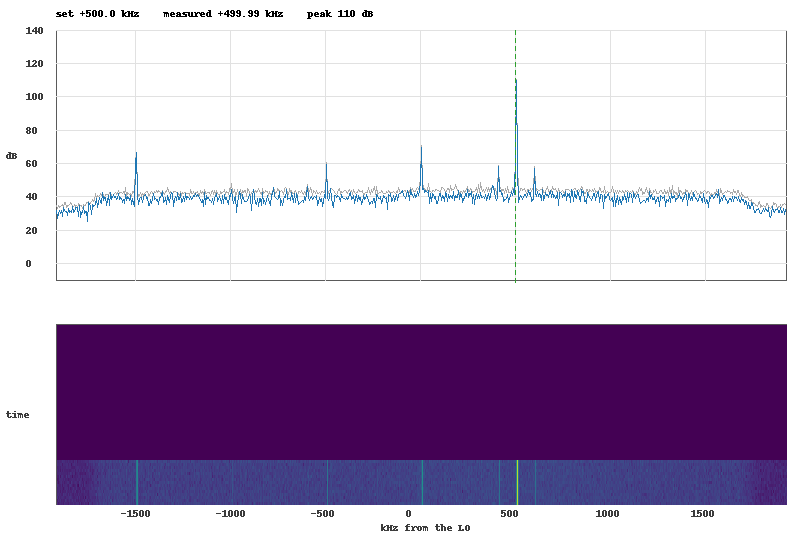

PASS  live thread with sweep: 28 frames in 3 s, the DDS was moved by the thread (now -21 kHz)


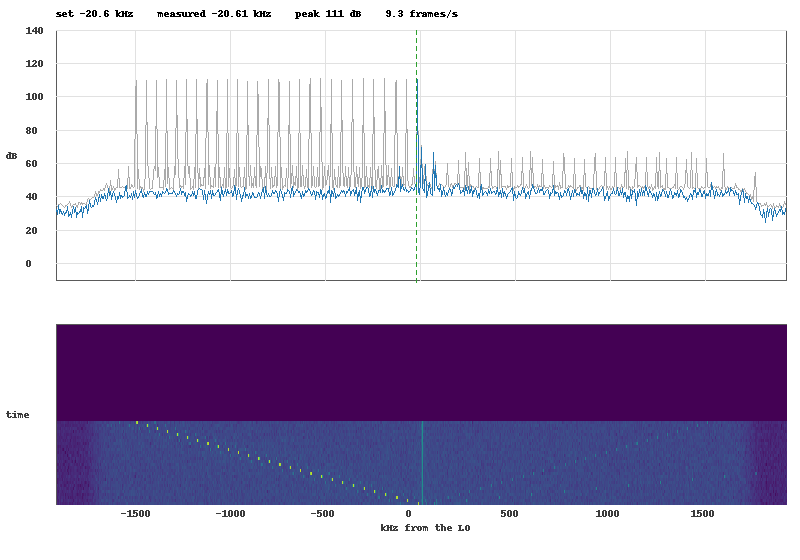

In [5]:
dds.set(freq_hz=500e3, amp=0.5)
reset_traces()
n = 15; t0 = time.time()
for i in range(n):
    ok, x = grab()
    png = render(spectrum_db(x), 500e3)
fps = n / (time.time() - t0)
f_pk, l_pk = peak_of(spectrum_db(x))
check("live frames", ok and abs(f_pk - 500e3) < 300 and fps > 5, f"{fps:.1f} frames/s, tone at {f_pk/1e3:.2f} kHz, {l_pk:.0f} dB")
display(IPImage(png))

# the same chain in the background thread, with the sweep on, for 3 s (this is what the Start button does)
sweep_box, img_w, st = widgets.Checkbox(value=True), widgets.Image(format="png"), widgets.Label()
lv = Live(img_w, st, {"sweep": sweep_box}); reset_traces()
lv.start(); time.sleep(3); lv.stop()
check("live thread with sweep", lv.frames > 10 and len(img_w.value) > 1000,
      f"{lv.frames} frames in 3 s, the DDS was moved by the thread (now {dds.freq_hz/1e3:+.0f} kHz)")
display(IPImage(img_w.value))

## Controls

* **Transmit**: the DDS enable. Off = zeros to the DAC (the transmitter itself stays powered, see *Stop and silence*).
* **Frequency / Amplitude**: written to the DDS registers as you move the slider.
* **Sweep**: the thread moves the frequency from -1.5 to +1.5 MHz in 6 s, over and over (the max-hold trace draws the whole band).
* **Digital loopback**: the chip feeds its TX data back to its RX data port: you see the DDS without the analog part (no antennas needed).
* **Start / Stop**: the live display. Stopping the display does *not* stop the tone.

In [6]:
w_tx   = widgets.Checkbox(value=True, description="Transmit")
w_freq = widgets.FloatSlider(value=500, min=-1800, max=1800, step=10, description="Freq (kHz)", continuous_update=True, layout=widgets.Layout(width="520px"))
w_amp  = widgets.FloatSlider(value=0.5, min=0, max=1, step=0.01, description="Amplitude", continuous_update=True, layout=widgets.Layout(width="520px"))
w_swp  = widgets.Checkbox(value=False, description="Sweep")
w_loop = widgets.Checkbox(value=False, description="Digital loopback")
b_start, b_stop = widgets.Button(description="Start", button_style="success"), widgets.Button(description="Stop", button_style="warning")
status = widgets.Label(value="idle")
image  = widgets.Image(format="png", width=720)
ui = {"sweep": w_swp}
live = Live(image, status, ui)

def guard(fn):
    def h(change=None):
        try:
            fn(change)
        except Exception as e:
            status.value = f"{type(e).__name__}: {e}"
    return h

w_freq.observe(guard(lambda c: (not w_swp.value) and dds.set(freq_hz=c["new"] * 1e3)), names="value")
w_amp.observe(guard(lambda c: dds.set(amp=c["new"])), names="value")
w_tx.observe(guard(lambda c: dds.set(enable=c["new"])), names="value")
w_loop.observe(guard(lambda c: ad.reg_write(OBS, (ad.reg_read(OBS) | 1) if c["new"] else (ad.reg_read(OBS) & ~1))), names="value")
b_start.on_click(guard(lambda b: (dds.set(freq_hz=w_freq.value * 1e3, amp=w_amp.value, enable=w_tx.value), reset_traces(), live.start())))
b_stop.on_click(guard(lambda b: live.stop()))

dds.set(freq_hz=w_freq.value * 1e3, amp=w_amp.value, enable=w_tx.value)
display(widgets.VBox([widgets.HBox([b_start, b_stop, status]), widgets.HBox([w_tx, w_swp, w_loop]), w_freq, w_amp, image]))

### Check the controls (optional)

Moves every control from Python, the same way a click would, and checks that the DDS registers follow. Skip it if you prefer to try the widgets by hand.

PASS  slider: frequency: DDS at 300.000 kHz
PASS  slider: amplitude: DDS amplitude 0.250
PASS  checkbox: transmit off: enabled = False
PASS  checkbox: transmit on: enabled = True
PASS  checkbox: digital loopback: 0x01
PASS  buttons: start / stop: 25 frames, status: stopped after 25 frames


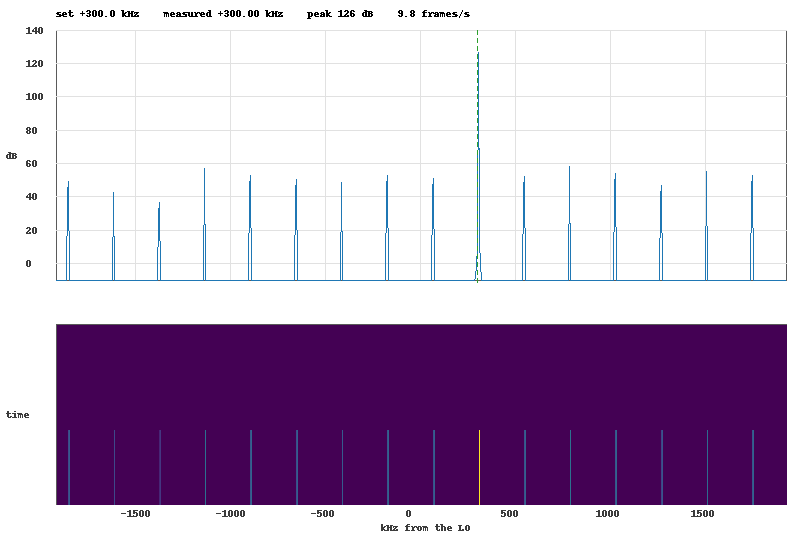

In [7]:
w_freq.value = 300;  check("slider: frequency", abs(dds.freq_hz - 300e3) < 1, f"DDS at {dds.freq_hz/1e3:.3f} kHz")
w_amp.value = 0.25;  check("slider: amplitude", abs(dds.amp - 0.25) < 0.001, f"DDS amplitude {dds.amp:.3f}")
w_tx.value = False;  check("checkbox: transmit off", not dds.enabled, f"enabled = {dds.enabled}")
w_tx.value = True;   check("checkbox: transmit on", dds.enabled, f"enabled = {dds.enabled}")
w_loop.value = True; check("checkbox: digital loopback", ad.reg_read(OBS) & 1, f"0x{ad.reg_read(OBS):02X}")
b_start.click(); time.sleep(2.5); b_stop.click()
check("buttons: start / stop", live.frames > 5 and not live.running and len(image.value) > 1000, f"{live.frames} frames, status: {status.value}")
w_loop.value = False
display(IPImage(image.value))

## Stop and silence

Run this when you are done (or after an error): it stops the display, turns the DDS off, switches the digital loopback off and puts the transmitter at a high attenuation
so almost nothing is radiated. The AD9361 transmit chain stays powered (a weak LO carrier remains), so reload an overlay or power down the board for complete silence.

In [8]:
try:
    live.stop()
finally:
    dds.off()
    ad.reg_write(OBS, ad.reg_read(OBS) & ~1)
    ad.set_tx_atten_db(80)
    print("DDS off, loopback off, TX attenuation 80 dB")

DDS off, loopback off, TX attenuation 80 dB
